## Question 3

### Imports and Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder




In [2]:
# 1. Load the dataset
df = pd.read_csv(r"C:\Users\KHABAZELA\OneDrive\Desktop\ITMLA2_Project\data\grid_restoration.csv")

### 3.1 Data Preparation

In [5]:
df.shape

(1000, 9)

In [3]:
df.head()

,Incident_ID,Affected_Line_Length_km,Fault_Category,Grid_Load_Level,Dispatch_Window,Crew_Type,Dispatch_Delay_Minutes,Technician_Experience_Years,Restoration_Time_Minutes
0,INC-0001,7.93,External Interference,Low,Day Shift,Mixed Crew,12,1.0,43
1,INC-0002,16.42,Equipment Failure,Medium,Late Shift,Standard Crew,20,2.0,84
2,INC-0003,9.52,Vegetation Contact,Low,Overnight,Mixed Crew,28,1.0,59
3,INC-0004,7.44,Cable Damage,Medium,Day Shift,Mixed Crew,5,1.0,37
4,INC-0005,19.03,Equipment Failure,Low,Early Shift,Standard Crew,16,5.0,68


In [4]:
# 2. Inspect missing values
print(df.isnull().sum())

Incident_ID                     0
Affected_Line_Length_km         0
Fault_Category                 30
Grid_Load_Level                30
Dispatch_Window                30
Crew_Type                       0
Dispatch_Delay_Minutes          0
Technician_Experience_Years    30
Restoration_Time_Minutes        0
dtype: int64


In [7]:
df.describe()

,Affected_Line_Length_km,Dispatch_Delay_Minutes,Technician_Experience_Years,Restoration_Time_Minutes
count,1000.000000,1000.000000,970.000000,1000.000000
mean,10.059970,16.982000,4.579381,56.732000
std,5.696656,7.204553,2.914394,22.070915
min,0.590000,5.000000,0.000000,8.000000
25%,5.105000,11.000000,2.000000,41.000000
50%,10.190000,17.000000,5.000000,55.500000
75%,15.017500,23.000000,7.000000,71.000000
max,19.990000,29.000000,9.000000,153.000000


### Impute Missing Values

In [8]:
# Fill numerical missing values with the median
df['Technician_Experience_Years'] = df['Technician_Experience_Years'].fillna(df['Technician_Experience_Years'].median())

# Fill categorical missing values with the mode (most frequent category)
categorical_missing = ['Fault_Category', 'Grid_Load_Level', 'Dispatch_Window']
for col in categorical_missing:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
Incident_ID                    0
Affected_Line_Length_km        0
Fault_Category                 0
Grid_Load_Level                0
Dispatch_Window                0
Crew_Type                      0
Dispatch_Delay_Minutes         0
Technician_Experience_Years    0
Restoration_Time_Minutes       0
dtype: int64


### Encode and Drop IDs

In [9]:
# Drop the non-predictive identifier
df = df.drop(columns=['Incident_ID'])

# Encode the categorical text variables into numbers
le = LabelEncoder()
categorical_cols = ['Fault_Category', 'Grid_Load_Level', 'Dispatch_Window', 'Crew_Type']

for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

print("Categorical features encoded successfully.")

Categorical features encoded successfully.


### 80/20 Split and Standardisation

In [ ]:
# Separate Features (X) and Target (y)
X = df.drop(columns=['Restoration_Time_Minutes'])
y = df['Restoration_Time_Minutes']

#  80/20 training and test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardise the predictors 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert y to NumPy arrays for our custom math later
y_train = y_train.values
y_test = y_test.values

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")

Training set shape: (800, 7)
Testing set shape: (200, 7)


#### 3.2 Custom Gradient Descent Implementation

In [11]:
# 1. Added a column of ones to X to represent the bias/intercept term (theta_0)
# X_train_scaled is currently (800, 7). We make it (800, 8) where the first column is all 1s.
X_train_b = np.c_[np.ones((X_train_scaled.shape[0], 1)), X_train_scaled]
X_test_b = np.c_[np.ones((X_test_scaled.shape[0], 1)), X_test_scaled]

# 2. Initialize parameters (theta) to zeros
# There are 8 parameters (1 bias + 7 features)
theta = np.zeros(X_train_b.shape[1])

# 3. Set Hyperparameters
learning_rate = 0.01
iterations = 1000
m = len(y_train) # Number of training examples

# 4. Initialize a list to store the cost history for the plot
cost_history = []

# 5. The Gradient Descent Loop
for i in range(iterations):
    # Step A: Calculate predictions
    y_pred = X_train_b.dot(theta)
    
    # Step B: Calculate the error (predictions - actual)
    error = y_pred - y_train
    
    # Step C: Calculate the Mean Squared Error (Cost)
    cost = (1 / (2 * m)) * np.sum(error ** 2)
    cost_history.append(cost)
    
    # Step D: Calculate the gradients (Partial derivatives)
    # The formula is: (1/m) * X_transpose * error
    gradients = (1 / m) * X_train_b.T.dot(error)
    
    # Step E: Update the parameters using the learning rate
    theta = theta - learning_rate * gradients

print("Gradient Descent Completed!")
print(f"Final Cost (MSE): {cost_history[-1]:.4f}")
print(f"Model Weights (Theta):\n{theta}")

Gradient Descent Completed!
Final Cost (MSE): 70.0969
Model Weights (Theta):
[57.05128692 17.35740688  1.28963293 -1.41009525  0.16433041  0.23780387
  7.03490563 -1.7611836 ]


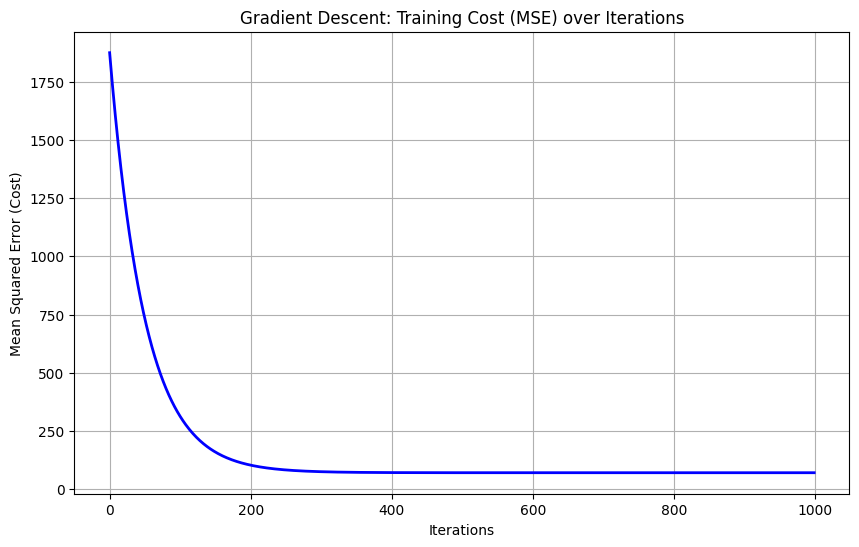

In [13]:
import os
# Plot the training cost over iterations
plt.figure(figsize=(10, 6))
plt.plot(range(iterations), cost_history, color='blue', linewidth=2)
plt.title('Gradient Descent: Training Cost (MSE) over Iterations')
plt.xlabel('Iterations')
plt.ylabel('Mean Squared Error (Cost)')
plt.grid(True)
plt.savefig('../outputs/figures/q3_gradient_descent_cost.png', dpi=300, bbox_inches='tight')
plt.show()

###  Evaluation on the Test Set

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Make predictions on the test set using the trained theta values
# Remember we added the column of 1s to X_test earlier (X_test_b)
y_pred_test = X_test_b.dot(theta)

# 2. Calculate the metrics
mae = mean_absolute_error(y_test, y_pred_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2 = r2_score(y_test, y_pred_test)

# 3. Print the results
print("--- Model Evaluation on Test Set ---")
print(f"Mean Absolute Error (MAE): {mae:.2f} minutes")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} minutes")
print(f"R-squared (R2) Score: {r2:.4f}")